# Lifestyle-Based Vitamin D Deficiency Screening Model in Asian Adults

Vitamin D deficiency is a common nutritional deficiency resulting from limited sun exposure, modern indoor lifestyles, and inadequate dietary intake. Prolonged deficiency negatively affects bone health and increases the risk of osteopenia and osteoporosis. Diagnosis relies on serum 25-hydroxyvitamin D testing (defined as < 50 nmol/L), which may not be readily accessible or affordable in rural primary care settings in Thailand, potentially leading to under-recognition and delayed management.

This project uses continuous data from the National Health and Nutrition Examination Survey (NHANES) across four cycles from 2011 to 2018, focusing specifically on non-pregnant Asian adults aged 20–59 years (N = 1,935). Machine-learning models—comparing Random Forest and XGBoost algorithms—are developed using non-invasive lifestyle and clinical indicators, including weekly sunlight exposure, sun-protective behaviors (sunscreen, long sleeves, shade), vitamin D supplementation, BMI, age, gender and smoking status, to investigate risk factors and screen for deficiency.

The objective is to develop a practical, non-invasive screening tool for primary care settings with limited access to laboratory testing. The tool helps identify high-risk individuals who would benefit from targeted lifestyle counseling, confirmatory testing, or timely vitamin D supplementation, with direct applications in preventive medicine and targeted health promotion.

## Import Packages and Load Dataset


### Import packages

In [1]:
import io
import urllib.request

import pandas as pd 
import numpy as np
import math

import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,\
    confusion_matrix, ConfusionMatrixDisplay,\
    roc_auc_score, RocCurveDisplay, brier_score_loss
from sklearn.calibration import calibration_curve

import shap

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load dataset

This project uses NHANES data from NCHS, CDC, covering 4 continuous cycles (2011–2012, 2013–2014, 2015–2016, and 2017–2018), totaling 8 years of continuous survey data. Demographic information, serum 25-hydroxyvitamin D, sun exposure behaviors, body measures, dietary supplements and smoking are extracted and merged by participant ID (`SEQN`).

In [2]:

duration_mapping = {
    '2011-2012': 'G',
    '2013-2014': 'H',
    '2015-2016': 'I',
    '2017-2018': 'J',
}

module = [
    'DEMO',     #Demographic Variables & Sample Weights
    'VID',      #25-Hydroxyvitamin D
    'DEQ',      #Dermatology
    'BMX',      #Body Measures
    'DSQTOT',   #Dietary Supplement
    'SMQRTU',   #Smoking
]

variable_mapping = {
    'id'                : 'SEQN',
    'race'              : 'RIDRETH3',
    'vitamin_d_level'   : 'LBXVIDMS',
    'age'               : 'RIDAGEYR',
    'gender'            : 'RIAGENDR',
    'pregnancy_status'  : 'RIDEXPRG',
    'bmi'               : 'BMXBMI',
    'supplement'        : 'DSD010',
    'vitd_supplement'   : 'DSQTVD',
    'sun_workdays'      : 'DED120',
    'sun_non_workdays'  : 'DED125',
    'stay_in_shade'     : 'DEQ034A',
    'wear_sleeves'      : 'DEQ034C',
    'use_sunscreen'     : 'DEQ034D',
    'smoke_5d_g'        : 'SMQ680',
    'smoke_5d_hij'      : 'SMQ681'

}

def fetch_xpt(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as response:
        content = response.read()
    return pd.read_sas(io.BytesIO(content), format="xport")

target_nhanes_codes = set(variable_mapping.values())

raw_df = None

for year_range, letter in duration_mapping.items():
    start_year = year_range.split('-')[0]
    cycle_merged = None
    for mod in module:
        url = (
        f'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/'
        f'{start_year}/DataFiles/{mod}_{letter}.xpt'
        )
        try:
            df = fetch_xpt(url)
            keep_cols = [c for c in df.columns if c in target_nhanes_codes]
            df_filtered = df[keep_cols]

            if cycle_merged is None:
                cycle_merged = df_filtered
            else:
                cycle_merged = pd.merge(cycle_merged, df_filtered, on='SEQN', how='left')

        except Exception as e:
            print(f'fail to load {mod}_{letter}: {e}')

    if raw_df is None:
        raw_df = cycle_merged
    else:
        raw_df = pd.concat([raw_df, cycle_merged], ignore_index=True)

df = raw_df.rename(columns={code: name for name, code in variable_mapping.items()})
df.to_csv('../data/nhanes_vitd_2011_2018.csv', index=False)

The study sample was filtered based on the following clinical criteria:
- **Target population**: Asian adults aged 20–59 years (`RIDRETH3 == 6.0`, `20 <= RIDAGEYR < 60`).
- **Inclusion criteria**: Included only participants with valid serum 25-hydroxyvitamin D measurements (`LBXVIDMS.notna()`).
- **Exclusion criteria**: Excluded confirmed pregnant individuals (`RIDEXPRG == 1`).

In [3]:
df = df[(df['age'] >= 20)\
            & (df['age'] < 60)\
            & (df['vitamin_d_level'].notna())\
            & (df['race'] == 6.0)\
            & (df['pregnancy_status'] != 1)].copy()
df = df.drop(columns=['race', 'pregnancy_status'])

## Exploratory Data Analysis


### Basic information about the data

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1935 entries, 8 to 39143
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                1935 non-null   float64
 1   gender            1935 non-null   float64
 2   age               1935 non-null   float64
 3   vitamin_d_level   1935 non-null   float64
 4   stay_in_shade     1935 non-null   float64
 5   wear_sleeves      1907 non-null   float64
 6   use_sunscreen     1907 non-null   float64
 7   sun_workdays      1933 non-null   float64
 8   sun_non_workdays  1933 non-null   float64
 9   bmi               1914 non-null   float64
 10  supplement        1935 non-null   float64
 11  vitd_supplement   716 non-null    float64
 12  smoke_5d_g        415 non-null    float64
 13  smoke_5d_hij      1172 non-null   float64
dtypes: float64(14)
memory usage: 226.8 KB


In [5]:
df.head()

,id,gender,age,vitamin_d_level,stay_in_shade,wear_sleeves,use_sunscreen,sun_workdays,sun_non_workdays,bmi,supplement,vitd_supplement,smoke_5d_g,smoke_5d_hij
8,62169.0,1.0,21.0,25.8,3.0,5.0,4.0,1.200000e+02,6.000000e+01,20.1,2.0,NaN,2.0,NaN
16,62177.0,1.0,51.0,58.5,2.0,3.0,5.0,1.200000e+02,1.200000e+02,20.1,2.0,NaN,NaN,NaN
18,62179.0,1.0,55.0,64.7,2.0,3.0,3.0,5.397605e-79,1.200000e+02,27.6,1.0,8.333,2.0,NaN
28,62189.0,2.0,30.0,36.6,1.0,3.0,1.0,5.397605e-79,5.397605e-79,22.4,2.0,NaN,2.0,NaN
39,62200.0,1.0,42.0,88.8,1.0,1.0,1.0,5.397605e-79,5.397605e-79,27.6,1.0,17.500,2.0,NaN


### Exploring potential behavioral features

According to **NHANES protocols**, this dataset predominantly consists of self-reported survey data collected via structured questionnaires (with the exception of serum 25-hydroxyvitamin D, which was measured through laboratory examination). 

Because each questionnaire-based feature is governed by specific survey logic, skip patterns, and standardized missing/refusal codes (e.g., *Refused*, *Don't know*, or *Not applicable*), thorough exploratory analysis and domain-specific data cleaning are essential to ensure valid feature representations.

#### `sun_workdays` and `sun_non_workdays`

Asking about the time spent outdoors during the past 30 days. Recorded in total minutes per day.

- Question `sun_workdays`: "How much time did you usually spend outdoors between 9 in the morning and 5 in the afternoon on the days that you worked or went to school?"
- Question `sun_non_workdays`: "How much time did you usually spend outdoors between 9 in the morning and 5 in the afternoon on the days when you were not working or going to school?"

Special Code:
- 3333: "Does not work or go to school"
- 7777: Refused.
- 9999: Don't know.

**Handling & Feature Engineering Strategy (`sun_per_week`):**

1. **Distinguish True Missing from Contextual Skips:**
   - `7777` (Refused) and `9999` (Don't know) represent **true missing data** and are recoded to `NaN`.
   - `3333` is **not missing data**; it carries meaningful lifestyle context:
     - In `sun_workdays`: *"Does not work or go to school"*
     - In `sun_non_workdays`: *"Works 7 days a week (no non-workdays)"*
   - Therefore, `3333` is preserved temporarily during feature engineering so it is not confounded with true `NaN` values.

2. **Calculate Total Weekly Sun Exposure (`sun_per_week`):**
   Synthesize daily exposures into a single weekly metric (minutes/week) based on work status:
   - **Standard Schedule:** `(sun_workdays × 5) + (sun_non_workdays × 2)`
   - **Non-working / Students (`sun_workdays == 3333`):** Scaled across all 7 days as non-workdays $\rightarrow$ `sun_non_workdays × 7`
   - **Full-time 7-day Workers (`sun_non_workdays == 3333`):** Scaled across all 7 days as workdays $\rightarrow$ `sun_workdays × 7`
   - **True Missing:** Kept as `NaN`.

3. **Drop Redundant Columns:**
   Once `sun_per_week` is created, `sun_workdays` and `sun_non_workdays` are dropped to eliminate redundancy and multicollinearity.

In [6]:
cols = ['sun_workdays', 'sun_non_workdays']
df[cols] = df[cols].replace({7777: np.nan, 9999: np.nan}).round(2)

conditions = [
    (df['sun_workdays'].notna() & (df['sun_workdays'] != 3333)) & 
    (df['sun_non_workdays'].notna() & (df['sun_non_workdays'] != 3333)),
    
    (df['sun_workdays'] == 3333) & 
    (df['sun_non_workdays'].notna() & (df['sun_non_workdays'] != 3333)),
    
    (df['sun_workdays'].notna() & (df['sun_workdays'] != 3333)) & 
    (df['sun_non_workdays'] == 3333)
]

choices = [
    (df['sun_workdays'] * 5) + (df['sun_non_workdays'] * 2),
    df['sun_non_workdays'] * 7,
    df['sun_workdays'] * 7
]

df['sun_per_week'] = np.select(conditions, choices, default=np.nan)

df = df.drop(columns=cols)

#### `stay_in_shade`, `wear_sleeves` and `use_sunscreen`

`stay_in_shade`: "When you go outside on a very sunny day for more than one hour, how often do you stay in the shade?"
`wear_sleeves`: "When you go outside on a very sunny day for more than one hour, how often do you wear long sleeved shirts?"
`use_sunscreen`: "When you go outside on a very sunny day for more than one hour, how often do you use sunscreen?"
- 1: Always
- 2: Most of the time
- 3: Sometimes
- 4: Rarely
- 5: Never
- 6: Don't go out in the sun

Special Code: 77 = Refused, 99 = Don't know.

**Handling & Recoding:**
Reordered all categories into an ordinal risk score from **0 to 5** (from *Never* [0] to *Don't go outside* [5]) directly reflecting increasing risk of Vitamin D deficiency:
- `0`: Never (lowest deficiency risk / maximum sun exposure)
- `1`: Rarely
- `2`: Sometimes
- `3`: Most of the time
- `4`: Always
- `5`: Don't go outside (highest deficiency risk / zero sun exposure)

Converted special codes (`77` = Refused, `99` = Don't know) to `NaN`.

In [7]:
protect_map = {
    77: np.nan,  # Refused
    99: np.nan,  # Don't know
    5: 0,  # Never
    4: 1,  # Rarely
    3: 2,  # Sometimes
    2: 3,  # Most of the time
    1: 4,  # Always
    6: 5,  # Don't go out in the sun
}

protect_cols = ["stay_in_shade", "wear_sleeves", "use_sunscreen"]

df[protect_cols] = df[protect_cols].replace(protect_map)

df.loc[df["stay_in_shade"] == 5, ["wear_sleeves", "use_sunscreen"]] = 5

#### `supplement` and `vitd_supplement`

- **Question:** 
  - `supplement` (`DSD010`): *"In the past 30 days, have you taken any dietary supplements, such as vitamins and minerals?"* (1 = Yes, 2 = No).
  - `vitd_supplement` (`DSQTVD`): Total daily Vitamin D intake calculated from all reported dietary supplements.
- **Response Format:** Continuous intake in micrograms per day ($\mu\text{g}$/day). Pre-existing `NaN` values represent participants who took no dietary supplements (947 participants) or whose reported supplements contained no Vitamin D (270 participants), both legitimately corresponding to zero supplemental Vitamin D intake (0 $\mu\text{g}$/day).
- **Special Codes:** `7` = Refused, `9` = Don't know (in `supplement`).

**Handling & Recoding:** 
- Imputed pre-existing `NaN` values with `0` for non-supplement users (`supplement == 2`) and non-Vitamin D supplement users (`supplement == 1` with blank intake).
- Converted special codes (`7`, `9`) to `NaN`.
- Dropped the redundant binary `supplement` column, retaining `vitd_supplement` as the continuous quantitative feature.

In [8]:
df.loc[df["supplement"] == 2, "vitd_supplement"] = 0

df.loc[
    (df["supplement"] == 1) & 
    (df["vitd_supplement"].isna()), "vitd_supplement"
] = 0

df["supplement"] = df["supplement"].replace([7, 9], np.nan)
df = df.drop(columns=["supplement"]).copy()

#### `smoke_5d_g` and `smoke_5d_hij`

- **Question:**: *"During the past 5 days, including today, did you smoke cigarettes, pipes, cigars, little cigars or cigarillos, water pipes, hookahs, or e-cigarettes?"*
- **Response Format:** Categorical binary response (`1` = Yes, `2` = No), 
- **Special Codes:** `7` = Refused, `9` = Don't know.

**Handling & Recoding:**
Recoded into a binary indicator `active_smoker`:
- `1`: Active user (reported smoking or vaping nicotine products within the past 5 days; `SMQ681 == 1`).
- `0`: Non-user (reported no recent tobacco or nicotine intake; `SMQ681 == 2`).
- Replaced special codes (`7`, `9`) with `NaN`.
- Dropped the intermediate raw column `smoke_5days`.

In [9]:
smoke_combined = df["smoke_5d_hij"].combine_first(df["smoke_5d_g"])

df["active_smoker"] = smoke_combined.replace({
    1: 1,
    2: 0,
    7: np.nan,
    9: np.nan
})

df = df.drop(columns=["smoke_5d_g", "smoke_5d_hij"])

### Check missing values

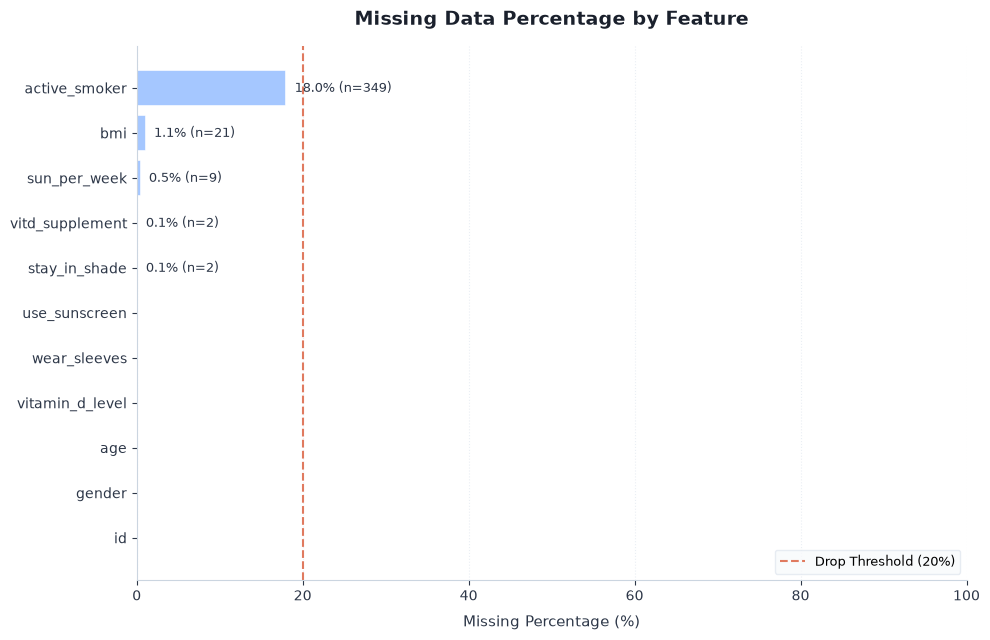

In [10]:
missing_df = (
    df.isna()
    .agg(["mean", "sum"])
    .T.rename(columns={"mean": "pct", "sum": "count"})
)
missing_df["pct"] = missing_df["pct"] * 100
missing_df = missing_df.sort_values(by="pct", ascending=True)

threshold = 20.0

colors = [
    "#FFB4A2" if pct > threshold else "#A0C4FF" for pct in missing_df["pct"]
]

fig, ax = plt.subplots(figsize=(10, 6.5))

bars = ax.barh(
    missing_df.index,
    missing_df["pct"],
    color=colors,
    edgecolor="white",
    linewidth=1.2,
    alpha=0.95,
)

for bar, (_, row) in zip(bars, missing_df.iterrows()):
  width = bar.get_width()
  if width > 0:
    ax.text(
        width + 1.0,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}% (n={int(row['count']):,})",
        va="center",
        fontsize=9,
        color="#2D3748",
    )

ax.axvline(
    threshold,
    color="#E07A5F",
    linestyle="--",
    linewidth=1.5,
    label=f"Drop Threshold ({threshold:.0f}%)",
)

ax.set_title(
    "Missing Data Percentage by Feature",
    fontsize=14,
    fontweight="bold",
    color="#1A202C",
    pad=15,
)
ax.set_xlabel("Missing Percentage (%)", fontsize=11, color="#2D3748", labelpad=8)
ax.set_xlim(0, max(missing_df["pct"].max() + 15, 100))

ax.grid(axis="x", linestyle=":", alpha=0.7, color="#E2E8F0")
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CBD5E0")
ax.spines["bottom"].set_color("#CBD5E0")

ax.tick_params(colors="#2D3748", labelsize=10)
ax.legend(
    loc="lower right",
    frameon=True,
    facecolor="#F8FAFC",
    edgecolor="#E2E8F0",
    fontsize=9,
)

plt.tight_layout()
plt.show()

### Check duplicated

In [11]:
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

id_col = "seqn" if "seqn" in df.columns else "id"
duplicate_ids = df.duplicated(subset=[id_col]).sum()
print(f"Total duplicate participant IDs: {duplicate_ids}")

Total duplicate rows: 0
Total duplicate participant IDs: 0


### Check outliers

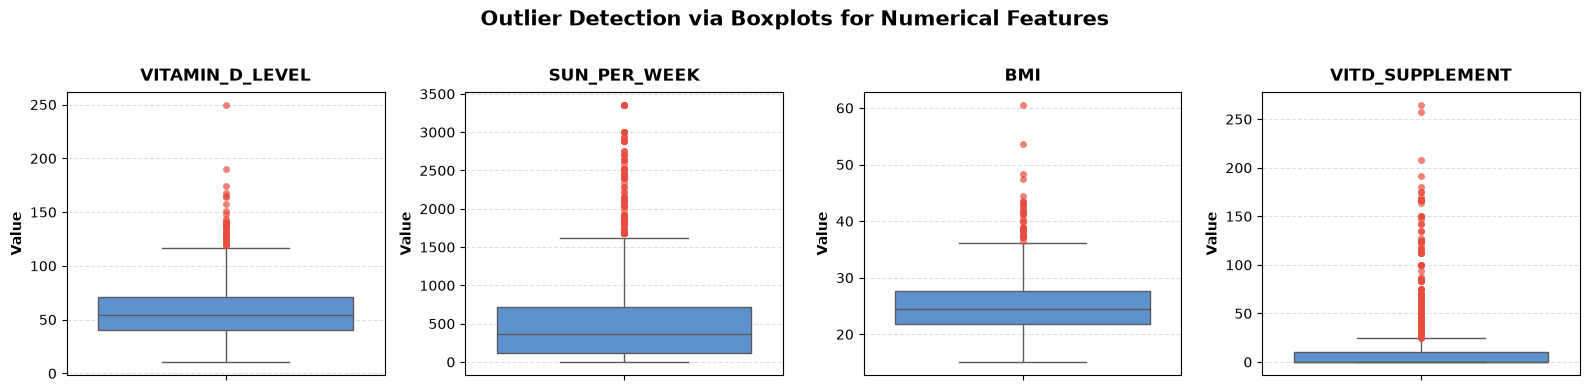

In [12]:
target_numeric_cols = [
    "vitamin_d_level",
    "sun_per_week",
    "bmi",
    "vitd_supplement"
]

numeric_cols = [col for col in target_numeric_cols if col in df.columns]

n_cols = 4
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(16, n_rows * 3.8), facecolor="white"
)
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
  sns.boxplot(
      y=df[col],
      ax=axes[i],
      color="#4a90e2",
      flierprops=dict(
          marker="o",
          markersize=5,
          markerfacecolor="#e74c3c",
          markeredgecolor="none",
          alpha=0.7,
      ),
  )

  axes[i].set_title(
      col.upper(), fontsize=12, fontweight="bold", color="black", pad=8
  )
  axes[i].set_ylabel("Value", fontsize=10, fontweight="bold", color="black")
  axes[i].tick_params(colors="black", labelsize=10)
  axes[i].grid(True, linestyle="--", alpha=0.4, axis="y")

# ลบช่องกราฟส่วนเกินที่ว่างอยู่ออก
for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.suptitle(
    "Outlier Detection via Boxplots for Numerical Features",
    fontsize=15,
    fontweight="bold",
    color="black",
    y=1.02,
)
plt.tight_layout()
plt.show()

### Data visualization

In [13]:
df.head()

,id,gender,age,vitamin_d_level,stay_in_shade,wear_sleeves,use_sunscreen,bmi,vitd_supplement,sun_per_week,active_smoker
8,62169.0,1.0,21.0,25.8,2.0,0.0,1.0,20.1,0.000,720.0,0.0
16,62177.0,1.0,51.0,58.5,3.0,2.0,0.0,20.1,0.000,840.0,NaN
18,62179.0,1.0,55.0,64.7,3.0,2.0,2.0,27.6,8.333,240.0,0.0
28,62189.0,2.0,30.0,36.6,4.0,2.0,4.0,22.4,0.000,0.0,0.0
39,62200.0,1.0,42.0,88.8,4.0,4.0,4.0,27.6,17.500,0.0,0.0


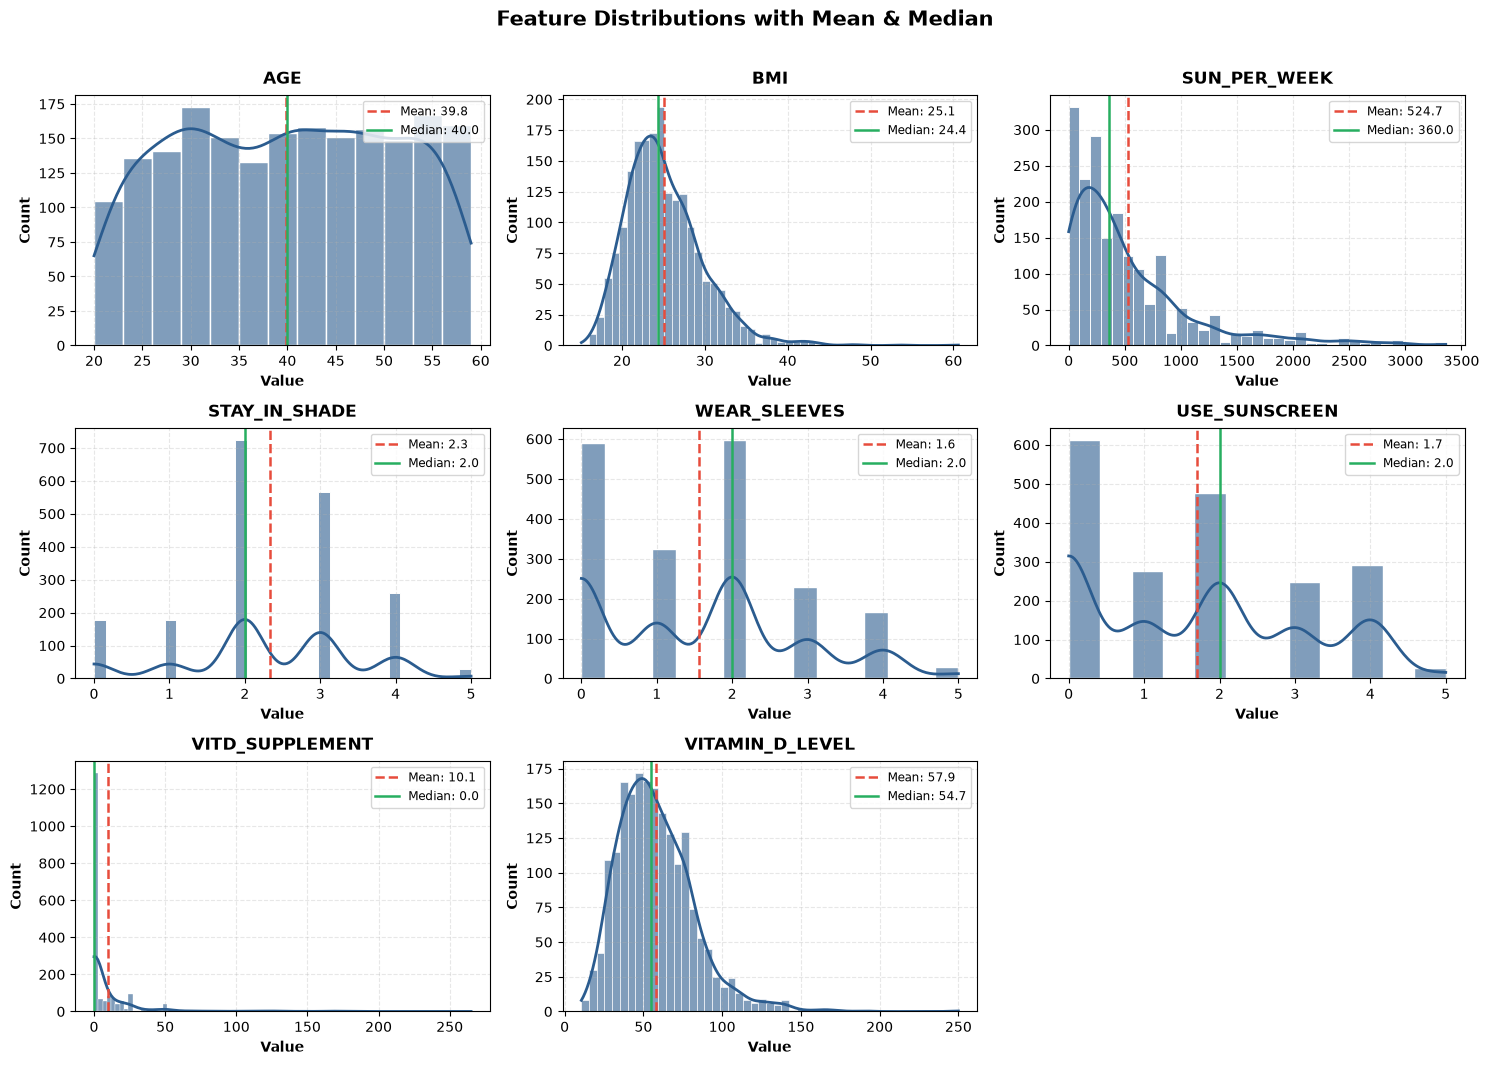

In [36]:
target_cols = [
    "age",
    "bmi",
    "sun_per_week",
    "stay_in_shade",
    "wear_sleeves",
    "use_sunscreen",
    "vitd_supplement",
    "vitamin_d_level",
]

numeric_cols = [col for col in target_cols if col in df.columns]

n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(15, n_rows * 3.5), facecolor="white"
)
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
  data = df[col].dropna()
  mean_val = data.mean()
  median_val = data.median()

  sns.histplot(
      data,
      kde=True,
      ax=axes[i],
      color="#2b5c8f",
      edgecolor="white",
      alpha=0.6,
      line_kws={"linewidth": 2},
  )

  axes[i].axvline(
      mean_val,
      color="#e74c3c",
      linestyle="--",
      linewidth=1.8,
      label=f"Mean: {mean_val:.1f}",
  )
  axes[i].axvline(
      median_val,
      color="#27ae60",
      linestyle="-",
      linewidth=1.8,
      label=f"Median: {median_val:.1f}",
  )

  axes[i].set_title(
      col.upper(), fontsize=12, fontweight="bold", color="black", pad=8
  )
  axes[i].set_xlabel("Value", fontsize=10, fontweight="bold", color="black")
  axes[i].set_ylabel("Count", fontsize=10, fontweight="bold", color="black")
  axes[i].tick_params(colors="black", labelsize=10)
  axes[i].legend(loc="upper right", fontsize=8.5, frameon=True)
  axes[i].grid(True, linestyle="--", alpha=0.3)

for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.suptitle(
    "Feature Distributions with Mean & Median",
    fontsize=15,
    fontweight="bold",
    color="black",
    y=1.01,
)
plt.tight_layout()
plt.show()

### Data structuring

Converted the gender column into a binary female column, identifying Female = 1 and Male = 0.

In [15]:
df["female"] = (df['gender'] == 2.0).astype(int)
df = df.drop(columns=['gender']).copy()

Target Variable: `vit_d_def` (Vitamin D Deficiency)

- **Source Measurement:** Serum 25-hydroxyvitamin D [25(OH)D] (`LBXVIDMS`), measured in **nmol/L**.
- **Clinical Definition:** Based on the Institute of Medicine (IOM) and Endocrine Society clinical practice guidelines:
  - **Deficient (`1`):** Serum $25(\text{OH})\text{D} < 50\text{ nmol/L}$ ($< 20\text{ ng/mL}$)
  - **Non-deficient / Sufficient (`0`):** Serum $25(\text{OH})\text{D} \ge 50\text{ nmol/L}$.

**Handling & Transformation:**
Created binary target `vit_d_def` and dropped the raw continuous measurement `vitamin_d_level` to prevent data leakage during model training.

In [16]:
df['vit_d_def'] = (df['vitamin_d_level'] < 50.0).astype(int)
df_final = df.drop(columns=['vitamin_d_level', 'id'])

## Feature Engineering

In [17]:
df_final.head()

,age,stay_in_shade,wear_sleeves,use_sunscreen,bmi,vitd_supplement,sun_per_week,active_smoker,female,vit_d_def
8,21.0,2.0,0.0,1.0,20.1,0.000,720.0,0.0,0,1
16,51.0,3.0,2.0,0.0,20.1,0.000,840.0,NaN,0,0
18,55.0,3.0,2.0,2.0,27.6,8.333,240.0,0.0,0,0
28,30.0,4.0,2.0,4.0,22.4,0.000,0.0,0.0,1,1
39,42.0,4.0,4.0,4.0,27.6,17.500,0.0,0.0,0,0


- **80:20 Split (`test_size=0.2`):** Allocates ~1,548 samples for training and 5-fold cross-validation, while reserving ~387 samples (162 deficiency cases) for independent clinical evaluation.
- **Stratification (`stratify=y`):** Preserves the ~41.9% vitamin D deficiency prevalence across both sets to prevent sampling bias.
- **Reproducibility:** A fixed `random_state` is used for reproducible results.

In [18]:
X = df_final.drop(columns='vit_d_def')
y = df_final['vit_d_def']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

## Model Develoment and Evaluation

### Random Forest Model

In [19]:
rf = RandomForestClassifier(
    class_weight='balanced',
    random_state=0) 

rf_params = {'n_estimators' : [100, 150, 200], 
              'max_depth' : [5, 10, 15, None],        
              'min_samples_leaf' : [1, 2, 4], 
              'min_samples_split' : [2, 5, 8],
              'max_features' : ['sqrt', 0.5], 
              'max_samples' : [0.7, 0.9, None]}

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

rf_cv = GridSearchCV(rf, rf_params, scoring=scoring, cv=5, refit='roc_auc', n_jobs=-1)

In [20]:
rf_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...andom_state=0)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'max_features': ['sqrt', 0.5], 'max_samples': [0.7, 0.9, ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['accuracy', 'precision', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None chan

In [21]:
rf_cv.best_params_

{'max_depth': 5,
 'max_features': 'sqrt',
 'max_samples': 0.7,
 'min_samples_leaf': 4,
 'min_samples_split': 2,
 'n_estimators': 150}

In [22]:
rf_model = rf_cv.best_estimator_

y_preds_rf = rf_model.predict(X_test)
y_probs_rf = rf_model.predict_proba(X_test)[:, 1]

print("Accuracy :", f"{accuracy_score(y_test, y_preds_rf):.4f}")
print("Precision:", f"{precision_score(y_test, y_preds_rf):.4f}")
print("Recall   :", f"{recall_score(y_test, y_preds_rf):.4f}")
print("F1 Score :", f"{f1_score(y_test, y_preds_rf):.4f}")
print("ROC-AUC  :", f"{roc_auc_score(y_test, y_probs_rf):.4f}")

Accuracy : 0.6848
Precision: 0.5820
Recall   : 0.8765
F1 Score : 0.6995
ROC-AUC  : 0.7627


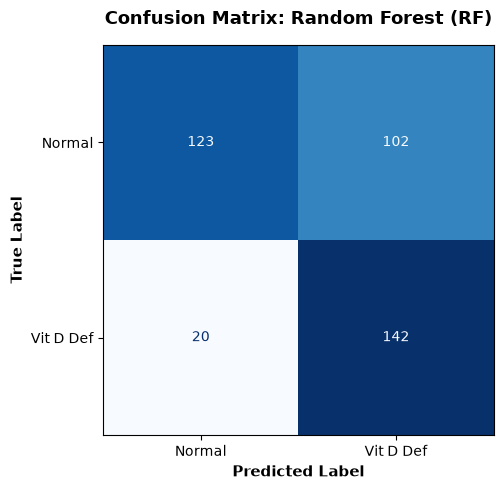

In [23]:
fig, ax = plt.subplots(figsize=(6, 5), facecolor='white')

rf_cm = confusion_matrix(y_test, y_preds_rf)
disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm, 
    display_labels=['Normal', 'Vit D Def']
)

disp.plot(ax=ax, cmap='Blues', colorbar=False)

ax.set_title("Confusion Matrix: Random Forest (RF)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Predicted Label", fontsize=11, fontweight='bold')
ax.set_ylabel("True Label", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### XGBoost Model

In [24]:

xgb = XGBClassifier(
    scale_pos_weight=(y_train.value_counts()[0] / y_train.value_counts()[1]),
    random_state=0)

xgb_params = {
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.03, 0.05, 0.1],
    'n_estimators': [100, 150, 200],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_cv = GridSearchCV(xgb, xgb_params, scoring=scoring, cv=5, refit='roc_auc', verbose=1, n_jobs=-1)


In [25]:
xgb_cv.fit(X_train, y_train)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.03, 0.05, ...], 'max_depth': [3, 4, ...], 'n_estimators': [100, 150, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['accuracy', 'precision', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if Non

In [26]:
xgb_cv.best_params_

{'colsample_bytree': 1.0,
 'learning_rate': 0.03,
 'max_depth': 3,
 'n_estimators': 100,
 'subsample': 0.8}

In [27]:
xgb_model = xgb_cv.best_estimator_

y_preds_xgb = xgb_model.predict(X_test)
y_probs_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("Accuracy :", f"{accuracy_score(y_test, y_preds_xgb):.4f}")
print("Precision:", f"{precision_score(y_test, y_preds_xgb):.4f}")
print("Recall   :", f"{recall_score(y_test, y_preds_xgb):.4f}")
print("F1 Score :", f"{f1_score(y_test, y_preds_xgb):.4f}")
print("ROC-AUC  :", f"{roc_auc_score(y_test, y_probs_xgb):.4f}")

Accuracy : 0.6925
Precision: 0.5885
Recall   : 0.8827
F1 Score : 0.7062
ROC-AUC  : 0.7668


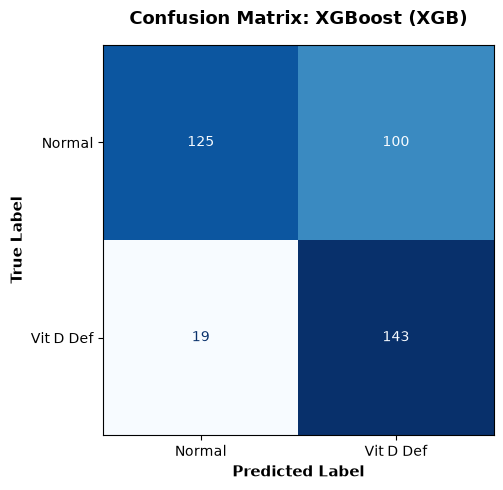

In [28]:
fig, ax = plt.subplots(figsize=(6, 5), facecolor='white')

xgb_cm = confusion_matrix(y_test, y_preds_xgb)
disp = ConfusionMatrixDisplay(
    confusion_matrix=xgb_cm, 
    display_labels=['Normal', 'Vit D Def']
)

disp.plot(ax=ax, cmap='Blues', colorbar=False)

ax.set_title("Confusion Matrix: XGBoost (XGB)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Predicted Label", fontsize=11, fontweight='bold')
ax.set_ylabel("True Label", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## Model Comparison and Calibration

In [29]:
models = {
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall (Sensitivity)': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

df_summary = pd.DataFrame(results)
display(df_summary.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall (Sensitivity)': '{:.4f}',
    'F1-Score': '{:.4f}',
    'ROC-AUC': '{:.4f}'
}))

,Model,Accuracy,Precision,Recall (Sensitivity),F1-Score,ROC-AUC
0,Random Forest,0.6848,0.5820,0.8765,0.6995,0.7627
1,XGBoost,0.6925,0.5885,0.8827,0.7062,0.7668


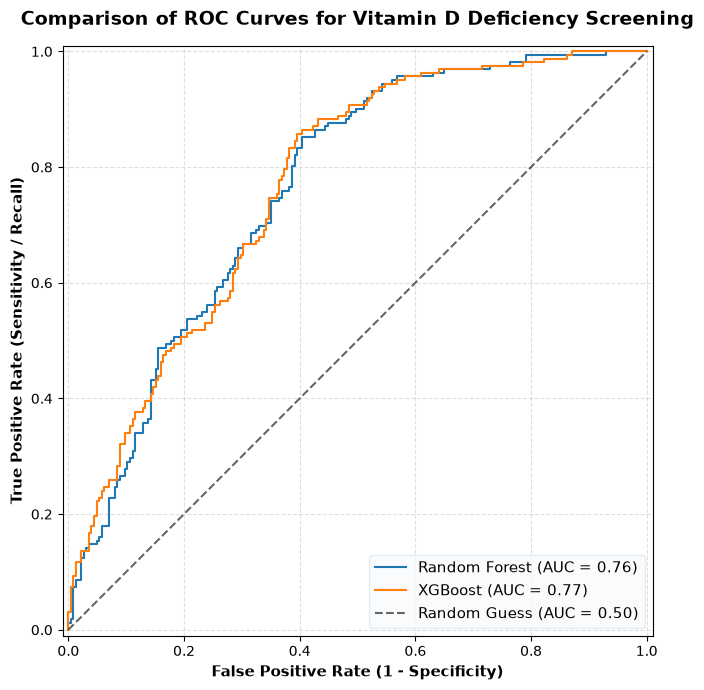

In [30]:
fig, ax = plt.subplots(figsize=(8, 7), facecolor='white')

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model, 
        X_test, 
        y_test, 
        ax=ax, 
        name=name
    )

ax.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Random Guess (AUC = 0.50)')

ax.set_title("Comparison of ROC Curves for Vitamin D Deficiency Screening", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11, fontweight='bold')
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11, fontweight='bold')
ax.legend(loc='lower right', fontsize=11, frameon=True, facecolor='#F8FAFC', edgecolor='#E2E8F0')
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Model Calibration & Bootstrap 95% Confidence Intervals

Evaluating model reliability using stratified bootstrap resampling ($N = 2,000$) to derive 95% confidence intervals for clinical metrics and probability calibration curves with Brier score.

Test set: n=387, positive=162, positive proportion=41.9%
Estimates with stratified bootstrap 95% confidence intervals:


,,Accuracy,Sensitivity,Specificity,PPV,NPV,F1,ROC-AUC,Brier score
Model,Threshold,,,,,,,,
Random Forest,0.5,"0.685 [0.641, 0.726]","0.877 [0.827, 0.926]","0.547 [0.484, 0.613]","0.582 [0.545, 0.620]","0.860 [0.805, 0.911]","0.700 [0.662, 0.736]","0.763 [0.712, 0.806]","0.197 [0.181, 0.213]"
XGBoost,0.5,"0.693 [0.649, 0.734]","0.883 [0.827, 0.932]","0.556 [0.489, 0.618]","0.588 [0.552, 0.626]","0.868 [0.816, 0.918]","0.706 [0.670, 0.742]","0.767 [0.719, 0.812]","0.196 [0.180, 0.214]"



Confusion matrix counts:


,Model,Threshold,TN,FP,FN,TP
0,Random Forest,0.5,123,102,20,142
1,XGBoost,0.5,125,100,19,143


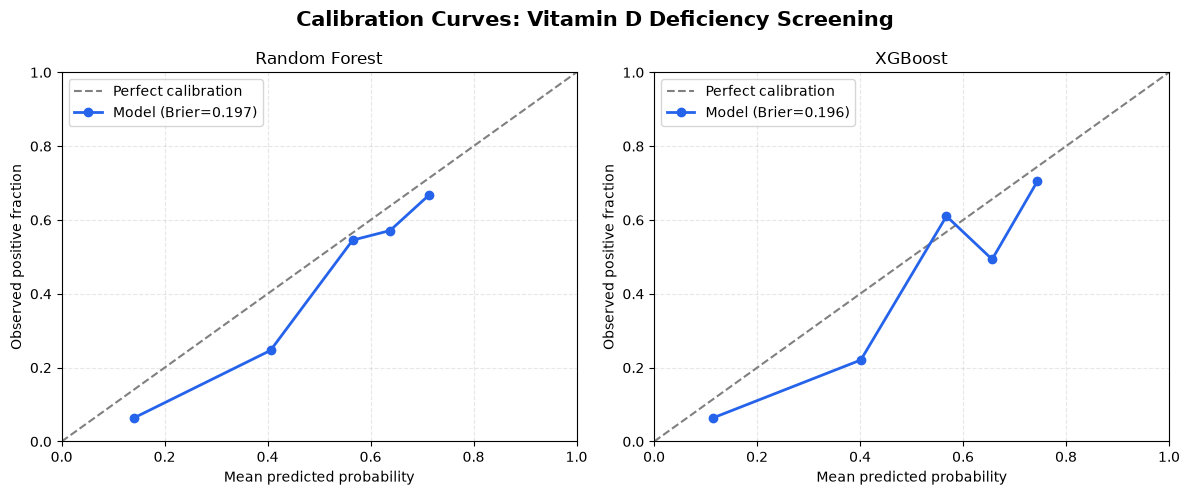

In [31]:
N_BOOTSTRAP = 2000
RANDOM_STATE = 0

thresholds = {name: 0.50 for name in models}
y_true = np.asarray(y_test, dtype=int)

if set(np.unique(y_true)) != {0, 1}:
    raise ValueError("y_test must contain both classes: 0 and 1.")

def safe_divide(numerator, denominator):
    return numerator / denominator if denominator > 0 else np.nan

def calculate_metrics(y, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[0, 1]).ravel()

    return {
        "Accuracy": safe_divide(tp + tn, tp + tn + fp + fn),
        "Sensitivity": safe_divide(tp, tp + fn),
        "Specificity": safe_divide(tn, tn + fp),
        "PPV": safe_divide(tp, tp + fp),
        "NPV": safe_divide(tn, tn + fn),
        "F1": safe_divide(2 * tp, 2 * tp + fp + fn),
        "ROC-AUC": roc_auc_score(y, probabilities),
        "Brier score": brier_score_loss(y, probabilities),
    }

rng = np.random.default_rng(RANDOM_STATE)
positive_indices = np.flatnonzero(y_true == 1)
negative_indices = np.flatnonzero(y_true == 0)

# Stratified Bootstrap Indices
bootstrap_indices = [
    np.concatenate([
        rng.choice(positive_indices, size=len(positive_indices), replace=True),
        rng.choice(negative_indices, size=len(negative_indices), replace=True),
    ])
    for _ in range(N_BOOTSTRAP)
]

results_long = []
count_rows = []
probabilities_by_model = {}

for name, model in models.items():
    positive_column = np.flatnonzero(model.classes_ == 1)
    probabilities = np.asarray(
        model.predict_proba(X_test)[:, positive_column[0]],
        dtype=float,
    )

    probabilities_by_model[name] = probabilities
    threshold = thresholds[name]

    # Point Estimates
    point_estimates = calculate_metrics(y_true, probabilities, threshold)

    # Bootstrap
    bootstrap_results = pd.DataFrame([
        calculate_metrics(y_true[idx], probabilities[idx], threshold)
        for idx in bootstrap_indices
    ])

    for metric, estimate in point_estimates.items():
        valid_values = bootstrap_results[metric].dropna().to_numpy()
        if len(valid_values):
            lower, upper = np.quantile(valid_values, [0.025, 0.975])
        else:
            lower, upper = np.nan, np.nan

        results_long.append({
            "Model": name,
            "Threshold": threshold,
            "Metric": metric,
            "Estimate": estimate,
            "CI Lower": lower,
            "CI Upper": upper,
            "Valid bootstrap samples": len(valid_values),
        })

    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    count_rows.append({
        "Model": name,
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    })

df_metrics_ci = pd.DataFrame(results_long)
df_confusion_counts = pd.DataFrame(count_rows)

# สร้างตารางสรุป Estimate [95% CI]
df_display = df_metrics_ci.copy()
df_display["Estimate [95% CI]"] = df_display.apply(
    lambda row: f"{row['Estimate']:.3f} [{row['CI Lower']:.3f}, {row['CI Upper']:.3f}]",
    axis=1,
)

metric_order = [
    "Accuracy",
    "Sensitivity",
    "Specificity",
    "PPV",
    "NPV",
    "F1",
    "ROC-AUC",
    "Brier score",
]

df_summary_ci = (
    df_display
    .pivot(
        index=["Model", "Threshold"],
        columns="Metric",
        values="Estimate [95% CI]",
    )
    .reindex(columns=metric_order)
    .reindex([(name, thresholds[name]) for name in models], axis=0)
)
df_summary_ci.columns.name = None

print(f"Test set: n={len(y_true)}, positive={y_true.sum()}, positive proportion={y_true.mean():.1%}")
print("Estimates with stratified bootstrap 95% confidence intervals:")
display(df_summary_ci)

print("\nConfusion matrix counts:")
display(df_confusion_counts)

# พล็อตกราฟ Calibration Curves
n_cols = 2
n_rows = int(np.ceil(len(models) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, 5 * n_rows),
    squeeze=False,
    facecolor='white'
)

for ax, (name, probabilities) in zip(axes.ravel(), probabilities_by_model.items()):
    observed_fraction, mean_probability = calibration_curve(
        y_true,
        probabilities,
        n_bins=5,
        strategy="quantile",
    )
    brier = brier_score_loss(y_true, probabilities)

    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
    ax.plot(
        mean_probability,
        observed_fraction,
        marker="o",
        linewidth=2,
        color="#2563EB",
        label=f"Model (Brier={brier:.3f})",
    )

    ax.set(
        title=f"{name}",
        xlabel="Mean predicted probability",
        ylabel="Observed positive fraction",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.grid(alpha=0.3, linestyle="--")
    ax.legend(loc="best")

for ax in axes.ravel()[len(models):]:
    ax.set_visible(False)

fig.suptitle("Calibration Curves: Vitamin D Deficiency Screening", fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

## Champion Model Selection: XGBoost

### Clinical Threshold Optimization for Screening

In primary care and preventive health check-ups, high sensitivity (recall) is clinically prioritized to minimize false negatives and avoid missed cases of vitamin D deficiency. By lowering the decision threshold from the default **0.50** to a screening-oriented threshold of **0.35**, the screening sensitivity increases substantially from **88.27% to 95.06%** (capturing 154 out of 162 deficient individuals), while preserving an acceptable precision of **54.04%**. This trade-off ensures that high-risk patients are effectively captured for confirmatory evaluation and targeted preventive counseling.

In [37]:
y_pred_xgb_35 = (y_probs_xgb >= 0.35).astype(int)

xgb_comparison = pd.DataFrame({
    'Metric': ['Recall (Sensitivity)', 'Precision', 'F1-Score', 'Accuracy'],
    'Threshold 0.50': [
        f"{recall_score(y_test, y_preds_xgb)*100:.2f}%",
        f"{precision_score(y_test, y_preds_xgb)*100:.2f}%",
        f"{f1_score(y_test, y_preds_xgb):.4f}",
        f"{accuracy_score(y_test, y_preds_xgb)*100:.2f}%"
    ],
    'Threshold 0.35 (Screening)': [
        f"{recall_score(y_test, y_pred_xgb_35)*100:.2f}%",
        f"{precision_score(y_test, y_pred_xgb_35)*100:.2f}%",
        f"{f1_score(y_test, y_pred_xgb_35):.4f}",
        f"{accuracy_score(y_test, y_pred_xgb_35)*100:.2f}%"
    ]
})

display(xgb_comparison)

,Metric,Threshold 0.50,Threshold 0.35 (Screening)
0,Recall (Sensitivity),88.27%,95.06%
1,Precision,58.85%,54.23%
2,F1-Score,0.7062,0.6906
3,Accuracy,69.25%,64.34%


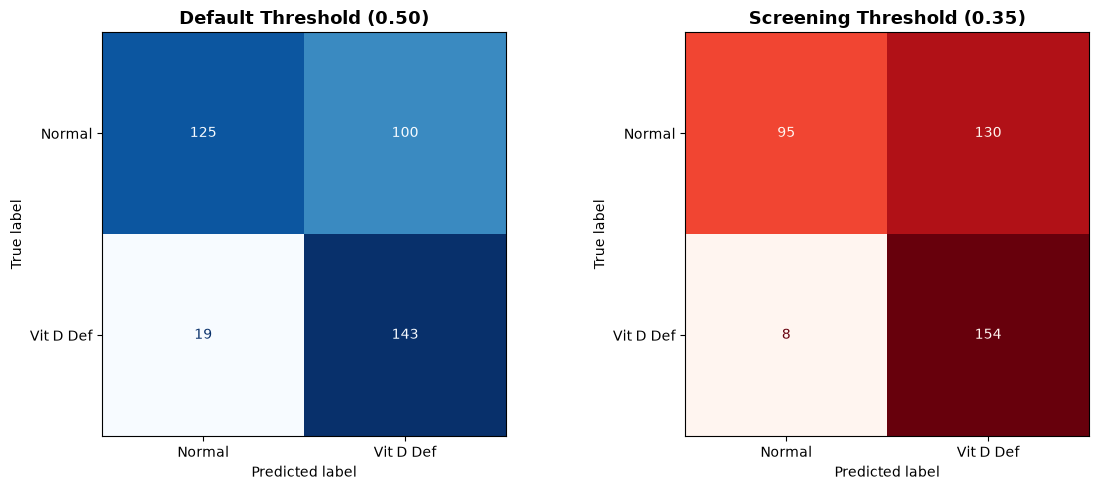

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor='white')

cm_50 = confusion_matrix(y_test, y_preds_xgb)
disp_50 = ConfusionMatrixDisplay(confusion_matrix=cm_50, display_labels=['Normal', 'Vit D Def'])
disp_50.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title("Default Threshold (0.50)", fontsize=13, fontweight='bold', color='black')

cm_35 = confusion_matrix(y_test, y_pred_xgb_35)
disp_35 = ConfusionMatrixDisplay(confusion_matrix=cm_35, display_labels=['Normal', 'Vit D Def'])
disp_35.plot(ax=axes[1], cmap='Reds', colorbar=False)
axes[1].set_title("Screening Threshold (0.35)", fontsize=13, fontweight='bold', color='black')

plt.tight_layout()
plt.show()

### Model Interpretability and Clinical Explanation (SHAP)

To ensure clinical transparency and explainability, SHAP (SHapley Additive exPlanations) values were computed to evaluate both global feature importance and individualized patient-level risk predictions.

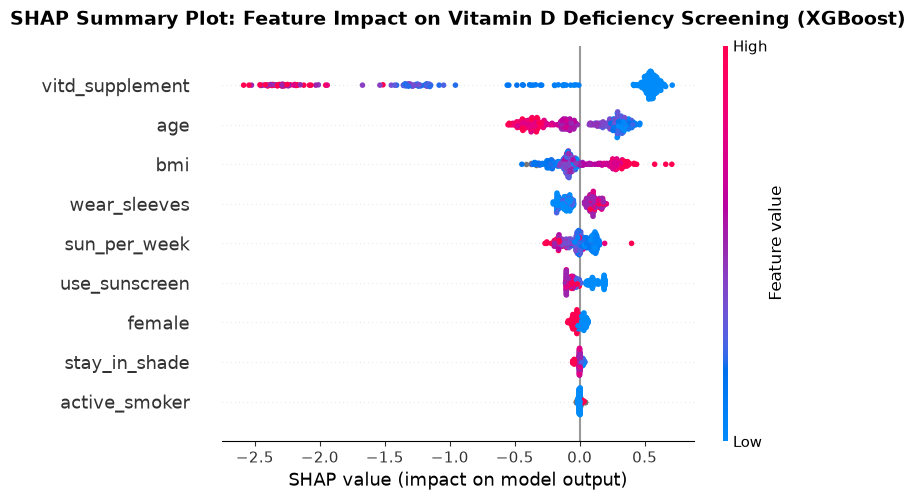

In [34]:
target_model = xgb_model

explainer = shap.TreeExplainer(target_model)
shap_values = explainer(X_test)

if len(shap_values.shape) == 3:
    shap_ida = shap_values[:, :, 1]
else:
    shap_ida = shap_values

plt.figure(figsize=(10, 6), facecolor='white')
plt.title("SHAP Summary Plot: Feature Impact on Vitamin D Deficiency Screening (XGBoost)", fontsize=14, fontweight='bold', pad=15)
shap.plots.beeswarm(shap_ida, max_display=12, show=False)
plt.tight_layout()
plt.show()

SHAP waterfall analysis is applied to evaluate individualized patient risk, illustrating how specific lifestyle, sun exposure, dietary supplement, and demographic features influence the prediction. This provides transparent and interpretable risk explanations that support clinician decision-making and targeted health counseling during routine primary care screenings.

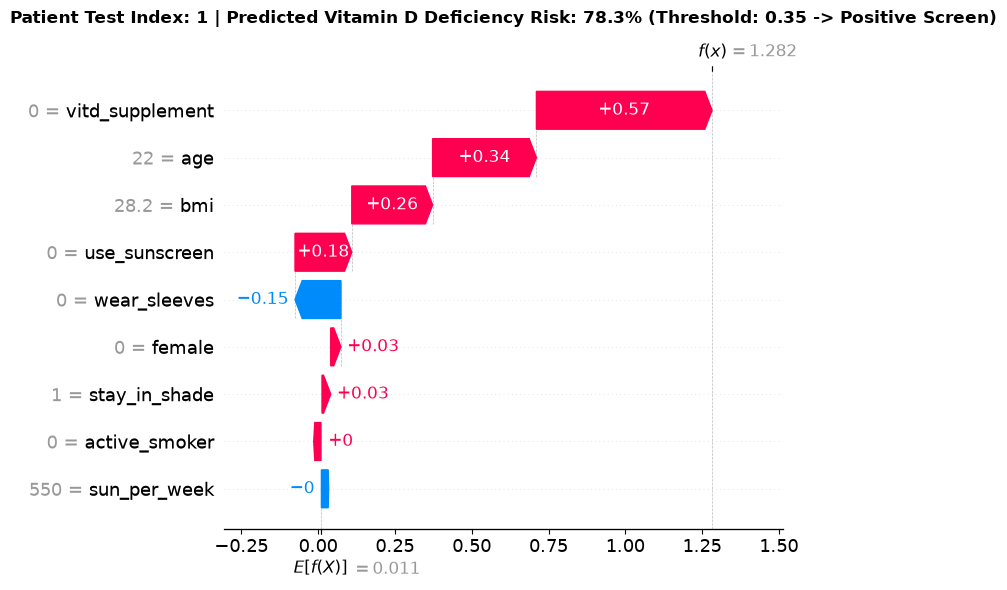

In [35]:
sample_idx = 1

prob_ida = target_model.predict_proba(X_test)[sample_idx, 1]
screening_threshold = 0.35
screening_result = "Positive Screen" if prob_ida >= screening_threshold else "Negative Screen"

plt.figure(figsize=(10, 6), facecolor='white')
shap.plots.waterfall(shap_ida[sample_idx], max_display=10, show=False)
plt.title(f"Patient Test Index: {sample_idx} | Predicted Vitamin D Deficiency Risk: {prob_ida:.1%} (Threshold: {screening_threshold:.2f} -> {screening_result})", 
          fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()